# Cirrhosis stage - JarvisTEC (`cirrhosis`)

**Team members:** Anthony Jafeth Arias Robleto (2020007243), Randy Espinoza Downing (2021031263), Kenneth Jhoan Araya Arguedas (2024177221)
**Dataset:** [Cirrhosis Prediction Dataset (Kaggle, fedesoriano/cirrhosis-prediction-dataset)](https://www.kaggle.com/datasets/fedesoriano/cirrhosis-prediction-dataset), the Mayo Clinic primary biliary cirrhosis (PBC) trial data published by Fleming & Harrington (1991).

| Section | Points |
|---|---|
| 1. Problem analysis | 0.5 |
| 2. Data understanding | 0.5 |
| 3. Data exploration | 0.5 |
| 4. Model | 2 |
| 5. Evaluation | 1 |
| 6. Conclusion | 0.5 |

## Configuration

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------- EDIT THESE VALUES -------------------------
# Must match `name` in backend/models/<package>/adapter.py.
MODEL_NAME = "cirrhosis"
# CSV path relative to training/<name>/ (data/ is git-ignored).
DATA_PATH = "../../data/cirrhosis/cirrhosis.csv"
TARGET_COLUMN = "stage"  # histologic stage of the disease, 1-4
TASK_TYPE = "classification"  # "classification" or "regression"
IS_TIME_SERIES = False  # True for bitcoin, avocado...: chronological split
DATE_COLUMN = None  # date column name when IS_TIME_SERIES is True
# id: identifier. n_days and status: follow-up time and outcome,
# only known AFTER the stage was assessed. drug: assigned at random.
# Justified in sections 2-4.
EXCLUDED_COLUMNS = ["id", "n_days", "status", "drug"]
SEED = 42
# ---------------------------------------------------------------------

ARTIFACTS = Path("../../artifacts")
ARTIFACTS.mkdir(exist_ok=True)
np.random.seed(SEED)
assert TASK_TYPE in ("classification", "regression")

## 1. Problem analysis

The goal is to estimate the **histologic stage of liver disease (1 to 4)** of a patient with primary biliary cirrhosis (PBC) from data that is cheap to obtain: age, sex, four findings of the physical examination and nine laboratory values. A histologic stage is normally established with a liver biopsy, an invasive procedure; a model that approximates it from routine data could help prioritize which patients need a closer look. The output is an **estimate to support a conversation with a physician, never a diagnosis**.

- **Task type:** multiclass classification with four **ordered** classes (`stage` 1, 2, 3, 4). The assignment asks to "classify the type of cirrhosis of a patient"; in this dataset the only variable that describes the type or degree of the disease is the histologic stage, so the four stages are kept as they are. The dataset documentation only names this column "histologic stage of disease" (1 to 4) and does not describe the individual stages, so no clinical meaning is attached to them here beyond their order. Merging stages (for example early vs. advanced) would be easier to predict, but it would no longer answer the question asked.
- **Success metrics:** **macro F1** (main metric: it averages the F1 of the four stages with equal weight, so the rare stage 1 counts as much as the others) and **balanced accuracy** (mean recall per stage). Accuracy is reported, but it rewards ignoring stage 1. Because the stages are ordered, the notebook also reports the share of predictions **within one stage** of the real one, the mean absolute error in stages and the quadratically weighted kappa: confusing stage 3 with 4 is less serious than confusing 1 with 4. The model is always compared with a baseline that predicts the most frequent stage.
- **Expectation:** the stage is assigned from a tissue sample, which blood tests reflect only indirectly, so modest results are expected.
- **Support:** Dickson et al. (1989) built the Mayo prognostic model for this same disease from age, bilirubin, albumin, prothrombin time and edema, which shows that these routine variables carry information about how advanced the disease is. The data is described in Fleming & Harrington (1991).

## 2. Data understanding

In [2]:
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (418, 20)


,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,2,4500,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,3,1012,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,4,1925,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,5,1504,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0


In [3]:
# snake_case names: the same fields the API receives
# (backend/models/cirrhosis/schema.py).
df.columns = [c.strip().lower() for c in df.columns]
df = df.rename(columns={"tryglicerides": "triglycerides"})
# Age comes in days; years are what a person would say to the assistant.
df["age"] = (df["age"] / 365.25).round(1)

# Patients of the randomized trial have a drug assigned. The others only
# had basic measurements recorded.
in_trial = df["drug"].notna()
group = in_trial.map({True: "trial", False: "not in trial"})
print("Patients in the trial:", int(in_trial.sum()))
print("Patients not in the trial:", int((~in_trial).sum()))
print("Missing values per column, by group:")
missing = df.isna().groupby(group).sum().T
display(missing[missing.sum(axis=1) > 0])

# Rows without the target cannot be used for supervised learning.
print("Rows without stage (dropped):", int(df["stage"].isna().sum()))
df = df.dropna(subset=["stage"]).reset_index(drop=True)
df["stage"] = df["stage"].astype(int)
print("Rows kept:", len(df))
display(df.head())

Patients in the trial: 312
Patients not in the trial: 106
Missing values per column, by group:


drug,not in trial,trial
drug,106,0
ascites,106,0
hepatomegaly,106,0
spiders,106,0
cholesterol,106,28
copper,106,2
alk_phos,106,0
sgot,106,0
triglycerides,106,30
platelets,7,4


Rows without stage (dropped): 6
Rows kept: 412


,id,n_days,status,drug,age,sex,ascites,hepatomegaly,spiders,edema,bilirubin,cholesterol,albumin,copper,alk_phos,sgot,triglycerides,platelets,prothrombin,stage
0,1,400,D,D-penicillamine,58.8,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4
1,2,4500,C,D-penicillamine,56.4,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3
2,3,1012,D,D-penicillamine,70.1,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4
3,4,1925,D,D-penicillamine,54.7,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4
4,5,1504,CL,Placebo,38.1,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3


In [4]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "% missing": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
display(summary)
print("Duplicated rows:", df.duplicated().sum())
display(df.describe(include="all").T)

,dtype,missing,% missing,unique
id,int64,0,0.00,412
n_days,int64,0,0.00,394
status,str,0,0.00,3
drug,str,100,24.27,2
age,float64,0,0.00,232
sex,str,0,0.00,2
ascites,str,100,24.27,2
hepatomegaly,str,100,24.27,2
spiders,str,100,24.27,2
edema,str,0,0.00,3


Duplicated rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,412.0,NaN,NaN,NaN,207.837379,120.888581,1.0,103.75,206.5,309.25,418.0
n_days,412.0,NaN,NaN,NaN,1916.837379,1099.941147,41.0,1094.25,1713.5,2610.5,4795.0
status,412,3,C,230,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drug,312,2,D-penicillamine,158,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,412.0,NaN,NaN,NaN,50.648058,10.466851,26.3,42.7,51.0,58.05,78.4
sex,412,2,F,368,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ascites,312,2,N,288,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hepatomegaly,312,2,Y,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
spiders,312,2,N,222,NaN,NaN,NaN,NaN,NaN,NaN,NaN
edema,412,3,N,348,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Data description.** Patients with primary biliary cirrhosis seen at the Mayo Clinic, from the trial of the drug D-penicillamine against placebo (Fleming & Harrington, 1991). The file has **418 patients** and 20 columns. **312** took part in the randomized trial and have nearly complete records; the other **106** were not in the trial and only had basic measurements recorded.

| Variable | Meaning | Type / assumed unit | Used |
|---|---|---|---|
| `id` | patient identifier | integer | no |
| `n_days` | days between registration and death, transplant or end of the study | integer | no |
| `status` | outcome: `C` censored, `CL` censored due to liver transplant, `D` death | categorical | no |
| `drug` | `D-penicillamine` or `Placebo` | categorical | no |
| `age` | age (in days in the file; converted to **years**) | years | yes |
| `sex` | `F` or `M` | categorical | yes |
| `ascites` | fluid in the abdomen | `Y` / `N` | yes |
| `hepatomegaly` | enlarged liver | `Y` / `N` | yes |
| `spiders` | spider angiomas on the skin | `Y` / `N` | yes |
| `edema` | `N` none, `S` present without diuretics or resolved by them, `Y` present despite diuretics | categorical | yes |
| `bilirubin` | serum bilirubin | mg/dl | yes |
| `cholesterol` | serum cholesterol | mg/dl | yes |
| `albumin` | serum albumin | g/dl | yes |
| `copper` | urine copper | ug/day | yes |
| `alk_phos` | alkaline phosphatase | U/liter | yes |
| `sgot` | SGOT (aspartate aminotransferase) | U/ml | yes |
| `triglycerides` | triglycerides (`Tryglicerides` in the file) | mg/dl | yes |
| `platelets` | platelets | thousands per cubic ml | yes |
| `prothrombin` | prothrombin time | seconds | yes |
| `stage` | histologic stage of the disease (**target**) | integer 1-4 | target |

**The laboratory units are an assumption.** The CSV file carries no units; those listed above are the ones usually quoted for this dataset and have not been confirmed against a primary source.

**Data quality:**
- **Rows without target:** 6 patients, all outside the trial, have no `stage`. They are dropped, because a supervised model cannot learn from them; **412 patients** remain (312 in the trial, 100 outside it).
- **Missing values (after that):** the 100 patients outside the trial lack `ascites`, `hepatomegaly`, `spiders`, `alk_phos` and `sgot` (24.3 % missing each), and also `cholesterol` (31.1 % missing in total), `triglycerides` (31.6 %) and `copper` (24.8 %): 8 of the 15 inputs. Inside the trial only cholesterol (28), triglycerides (30), platelets (4) and copper (2) have gaps. `platelets` (2.7 %) and `prothrombin` (0.5 %) are almost complete. Dropping those 100 patients would remove a quarter of an already small dataset, so they are kept and the values are **imputed inside the `Pipeline`** (median for numeric inputs, mode for categorical ones), fitted on the training data only. This also lets the backend answer when a value is not provided.
- **Duplicates:** none.
- **Age:** it comes in days (e.g. 21464) and is converted to years (58.8), which is what a person would say to the assistant. Ages range from 26.3 to 78.4 years, with a median of 51.0.
- **Columns excluded from the inputs**, with the evidence in section 3:
  - `id` is an identifier.
  - `n_days` and `status` describe what happened to the patient **after** the stage was assessed (how long they were followed and whether they died). They are not known when someone asks for the stage of a new patient, and they are a consequence of the stage, not a cause: using them would be information leakage.
  - `drug` was assigned at random when the patient entered the trial, so by design it carries no information about the stage at that moment, and it is missing for every patient outside the trial.

## 3. Data exploration

stage
3    37.62
4    34.95
2    22.33
1     5.10
Name: % of each class, dtype: float64

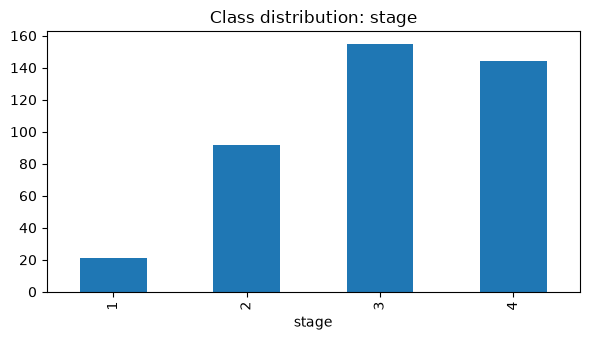

In [5]:
target = TARGET_COLUMN
fig, ax = plt.subplots(figsize=(6, 3.5))
if TASK_TYPE == "classification":
    df[target].value_counts().sort_index().plot(kind="bar", ax=ax)
    ax.set_title(f"Class distribution: {target}")
    shares = (df[target].value_counts(normalize=True) * 100).round(2)
    display(shares.rename("% of each class"))
else:
    df[target].plot(kind="hist", bins=40, ax=ax)
    ax.set_title(f"Distribution of {target}")
plt.tight_layout()
plt.show()

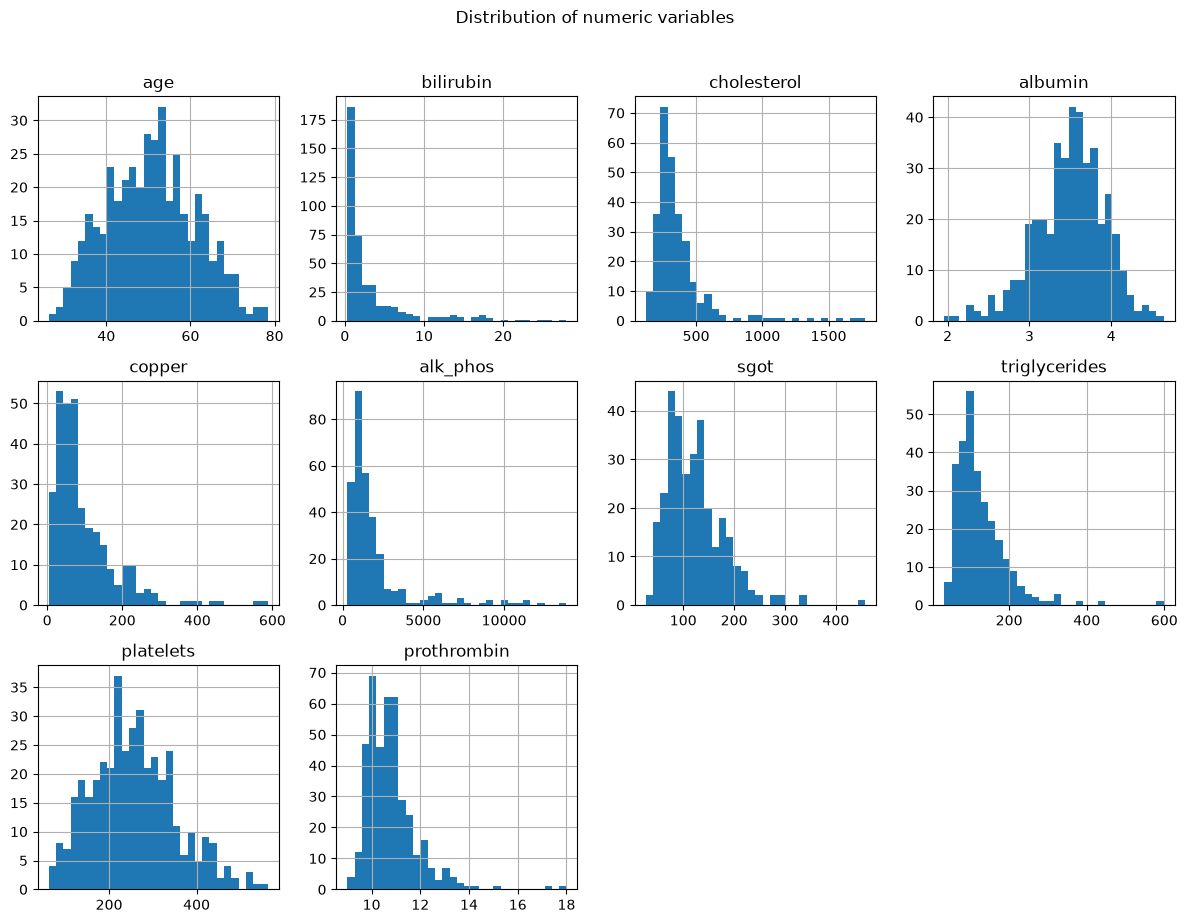

In [6]:
numeric_columns = [
    c for c in df.select_dtypes("number").columns
    if c not in EXCLUDED_COLUMNS + [target]
]
rows = (len(numeric_columns) + 3) // 4
df[numeric_columns].hist(bins=30, figsize=(12, 3 * rows), layout=(-1, 4))
plt.suptitle("Distribution of numeric variables", y=1.02)
plt.tight_layout()
plt.show()

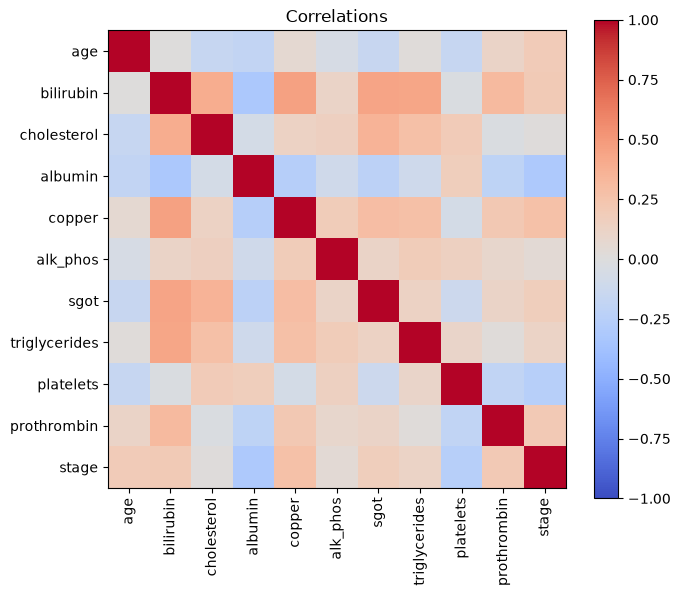

albumin         -0.305296
copper           0.269400
platelets       -0.253523
prothrombin      0.207802
bilirubin        0.200731
age              0.188966
sgot             0.164945
triglycerides    0.123899
alk_phos         0.041273
cholesterol      0.011164
Name: correlation with the target, dtype: float64

In [7]:
if len(numeric_columns) > 1:
    corr = df[numeric_columns + [target]].select_dtypes("number").corr()
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)))
    ax.set_yticklabels(corr.columns)
    plt.colorbar(image)
    ax.set_title("Correlations")
    plt.tight_layout()
    plt.show()
    if pd.api.types.is_numeric_dtype(df[target]):
        display(
            corr[target].drop(target)
            .sort_values(key=abs, ascending=False)
            .rename("correlation with the target")
        )

In [8]:
# Median of every numeric input by stage (the target is ordinal).
display(df.groupby(target)[numeric_columns].median().round(2).T)

# Share of each category by stage (rows with a recorded value only).
for column in ["sex", "ascites", "hepatomegaly", "spiders", "edema"]:
    display(pd.crosstab(df[target], df[column], normalize="index").round(3))

skew = df[numeric_columns].skew().round(2).sort_values(ascending=False)
display(skew.rename("skewness"))

stage,1,2,3,4
age,46.30,49.00,49.10,54.00
bilirubin,0.80,0.95,1.30,2.55
cholesterol,239.00,298.00,324.00,299.00
albumin,3.77,3.62,3.61,3.34
copper,64.00,49.50,67.50,98.50
alk_phos,706.00,1164.00,1257.50,1428.00
sgot,64.32,108.50,112.38,122.45
triglycerides,84.00,101.00,119.00,106.00
platelets,270.50,277.00,252.00,216.00
prothrombin,10.15,10.40,10.40,11.00


sex,F,M
stage,,
1,0.857,0.143
2,0.913,0.087
3,0.897,0.103
4,0.882,0.118


ascites,N,Y
stage,,
1,1.000,0.000
2,0.970,0.030
3,0.992,0.008
4,0.807,0.193


hepatomegaly,N,Y
stage,,
1,1.000,0.000
2,0.716,0.284
3,0.558,0.442
4,0.193,0.807


spiders,N,Y
stage,,
1,0.938,0.062
2,0.866,0.134
3,0.750,0.250
4,0.541,0.459


edema,N,S,Y
stage,,,
1,0.952,0.048,0.000
2,0.935,0.054,0.011
3,0.890,0.090,0.019
4,0.722,0.167,0.111


cholesterol      3.41
alk_phos         2.99
bilirubin        2.71
triglycerides    2.52
copper           2.30
prothrombin      2.22
sgot             1.45
platelets        0.44
age              0.11
albumin         -0.46
Name: skewness, dtype: float64

In [9]:
# Columns excluded from the inputs: how do they relate to the stage?
from scipy.stats import chi2_contingency

# drug: assigned at random when the patient entered the trial.
drug_table = pd.crosstab(df[target], df["drug"])
display(drug_table)
chi2, p_value, _, _ = chi2_contingency(drug_table)
print(f"drug vs. stage: chi2 = {chi2:.2f}, p = {p_value:.3f}")

# n_days and status: recorded at the END of the follow-up.
display(
    df.groupby(target)["n_days"].agg(["count", "median", "mean"]).round(0)
)
display(pd.crosstab(df[target], df["status"], normalize="index").round(3))
print(
    "Spearman correlation n_days vs. stage:",
    round(df["n_days"].corr(df[target], method="spearman"), 3),
)

drug,D-penicillamine,Placebo
stage,,
1,12,4
2,35,32
3,56,64
4,55,54


drug vs. stage: chi2 = 4.63, p = 0.201


,count,median,mean
stage,,,
1,21,2644.0,2655.0
2,92,2410.0,2390.0
3,155,1810.0,1997.0
4,144,1207.0,1420.0


status,C,CL,D
stage,,,
1,0.905,0.000,0.095
2,0.696,0.054,0.250
3,0.626,0.065,0.310
4,0.347,0.069,0.583


Spearman correlation n_days vs. stage: -0.384


In [10]:
categorical_columns = [
    c for c in df.select_dtypes(exclude="number").columns
    if c not in EXCLUDED_COLUMNS + [target, DATE_COLUMN]
]
for column in categorical_columns[:6]:
    print(f"\n{column}: {df[column].nunique()} categories")
    display(df[column].value_counts().head(10))


sex: 2 categories


sex
F    368
M     44
Name: count, dtype: int64


ascites: 2 categories


ascites
N    288
Y     24
Name: count, dtype: int64


hepatomegaly: 2 categories


hepatomegaly
Y    160
N    152
Name: count, dtype: int64


spiders: 2 categories


spiders
N    222
Y     90
Name: count, dtype: int64


edema: 3 categories


edema
N    348
S     44
Y     20
Name: count, dtype: int64

**Exploration findings:**

- **Imbalance:** stage 3 has 37.6 % of the patients, stage 4 35.0 %, stage 2 22.3 % and **stage 1 only 5.1 % (21 patients)**. A model can reach 37.6 % accuracy by always answering "stage 3". This motivates macro F1, a stratified split, and trying `class_weight="balanced"`.
- **Weak relationship with the stage:** the strongest linear correlations are **albumin** (-0.31), **copper** (0.27), **platelets** (-0.25), **prothrombin** (0.21), **bilirubin** (0.20) and **age** (0.19). None is strong; alkaline phosphatase (0.04) and cholesterol (0.01) show almost none. These are Pearson correlations, which treat the ordinal stage as a number with equal steps between stages, so they are only a rough guide; the medians by stage below are read together with them.
- **The signal is concentrated in stage 4:** for these variables the medians change little between stages 1, 2 and 3, and the largest step is at stage 4. Bilirubin goes 0.80, 0.95, 1.30 and then 2.55; albumin 3.77, 3.62, 3.61 and then 3.34; platelets 270.5, 277, 252 and then 216; prothrombin time 10.15, 10.4, 10.4 and then 11.0. Stages 2 and 3 look very similar in the blood tests, so the model is expected to confuse them.
- **Physical findings:** **hepatomegaly** is the clearest one: 0 % of the stage 1 patients, 28 % of stage 2, 44 % of stage 3 and 81 % of stage 4. Spider angiomas rise from 6 % in stage 1 to 46 % in stage 4. Ascites appears almost only in stage 4 (19 %). Edema is absent in 95 % of stage 1 and in 72 % of stage 4. Hepatomegaly, spider angiomas and ascites are not recorded for the patients outside the trial; edema is recorded for everyone.
- **Sex:** 368 women and 44 men, with similar proportions in every stage; it is not expected to help.
- **Skewed variables and outliers:** cholesterol (skewness 3.41, maximum 1775 against a median of 309.5), alkaline phosphatase (2.99, maximum 13862), bilirubin (2.71), triglycerides (2.52), copper (2.30) and prothrombin time (2.22) have long right tails. Such values are plausible for very sick patients, so they are kept. **No transformation (such as a logarithm) is applied to these variables.** The selected model is a tree ensemble: trees split on thresholds, so they are insensitive to monotone transformations of an input and little affected by extreme values. A transformation would matter for the linear candidates of section 4 (logistic regression), and for the distance-based ones (SVM, k-NN); they were compared without one, which may put them at a disadvantage, and this was not tested.
- **Excluded columns:**
  - `drug` shows no significant association with the stage (chi-square 4.63, p = 0.20), as expected from a random assignment.
  - `n_days` and `status` are clearly related to the stage: the median follow-up falls from 2644 days in stage 1 to 1207 in stage 4 (Spearman correlation -0.38), and the share of patients who died rises from 9.5 % to 58.3 %. This is exactly why they are not valid inputs: these columns record what happened to the patient after the stage was assessed.

**Preprocessing decisions:** drop the rows without `stage`; convert the age to years; exclude `id`, `n_days`, `status` and `drug`; impute missing values with the median (numeric) or the mode (categorical); scale the numeric variables (without a log transformation, for the reason given above) and one-hot encode the categorical ones, all inside the `Pipeline`.

## 4. Model

A baseline is compared with several models using cross-validation, and the best one is chosen. All preprocessing lives inside a `Pipeline`, so the backend receives raw data and there is no information leakage.

> **Time series:** with `IS_TIME_SERIES = True` the split is chronological (the test set is the most recent data) and cross-validation uses `TimeSeriesSplit`. Never shuffle the temporal order when splitting.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    TimeSeriesSplit,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Duplicates removed before splitting, so no row is in both sets.
data = df.drop_duplicates().copy()
if IS_TIME_SERIES and DATE_COLUMN:
    data[DATE_COLUMN] = pd.to_datetime(data[DATE_COLUMN])
    data = data.sort_values(DATE_COLUMN).reset_index(drop=True)

dropped = [TARGET_COLUMN] + EXCLUDED_COLUMNS
dropped += [DATE_COLUMN] if DATE_COLUMN else []
X = data.drop(columns=dropped)
y = data[TARGET_COLUMN]
numeric_features = X.select_dtypes("number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

if IS_TIME_SERIES:
    cut = int(len(X) * 0.8)
    X_train, X_test = X.iloc[:cut], X.iloc[cut:]
    y_train, y_test = y.iloc[:cut], y.iloc[cut:]
    cv = TimeSeriesSplit(n_splits=5)
else:
    stratify = (
        y if TASK_TYPE == "classification" and y.value_counts().min() >= 2
        else None
    )
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=SEED, stratify=stratify
    )
    cv = (
        StratifiedKFold(5, shuffle=True, random_state=SEED)
        if stratify is not None
        else KFold(5, shuffle=True, random_state=SEED)
    )

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])
print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

Train: (329, 15)  Test: (83, 15)
Numeric: ['age', 'bilirubin', 'cholesterol', 'albumin', 'copper', 'alk_phos', 'sgot', 'triglycerides', 'platelets', 'prothrombin']
Categorical: ['sex', 'ascites', 'hepatomegaly', 'spiders', 'edema']


In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

print("Training patients per stage:")
print(y_train.value_counts().sort_index().to_dict())
# Few patients (and very few of stage 1): a single 5-fold split is noisy,
# so the stratified 5-fold is repeated 3 times with different shuffles.
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

candidates = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=2000),
    "Logistic regression (balanced)": LogisticRegression(
        max_iter=2000, class_weight="balanced"
    ),
    "k-NN": KNeighborsClassifier(n_neighbors=15),
    "SVM (balanced)": SVC(
        class_weight="balanced", probability=True, random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=SEED, n_jobs=1
    ),
    "Random Forest (balanced)": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced",
        random_state=SEED, n_jobs=1,
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}
# Macro F1 selects the model; the other two are reported for context.
scoring = "f1_macro"
SCORES = ["f1_macro", "balanced_accuracy", "accuracy"]

score_column = f"{scoring} (mean)"
rows = []
for name, estimator in candidates.items():
    pipeline = Pipeline([("prep", preprocessor), ("model", estimator)])
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv, scoring=SCORES, n_jobs=1
    )
    rows.append({
        "model": name,
        score_column: scores["test_f1_macro"].mean(),
        "std": scores["test_f1_macro"].std(),
        "balanced_accuracy (mean)": scores["test_balanced_accuracy"].mean(),
        "accuracy (mean)": scores["test_accuracy"].mean(),
    })
comparison = (
    pd.DataFrame(rows)
    .sort_values(score_column, ascending=False)
    .reset_index(drop=True)
)
display(comparison.round(4))

Training patients per stage:
{1: 17, 2: 73, 3: 124, 4: 115}


,model,f1_macro (mean),std,balanced_accuracy (mean),accuracy (mean)
0,Random Forest (balanced),0.3993,0.0693,0.4249,0.4651
1,SVM (balanced),0.3899,0.0500,0.4269,0.4579
2,Logistic regression (balanced),0.3726,0.0543,0.4135,0.4286
3,Logistic regression,0.3665,0.0577,0.3750,0.4914
4,Random Forest,0.3615,0.0507,0.3757,0.5106
5,Gradient Boosting,0.3474,0.0578,0.3558,0.4691
6,k-NN,0.3209,0.0423,0.3305,0.4508
7,Baseline,0.1369,0.0010,0.2500,0.3769


In [13]:
# What would happen if the follow-up columns were used as inputs?
# Same cross-validation on TRAIN only; shown to justify the exclusion, the
# final model never sees these columns.
LEAK_COLUMNS = ["n_days", "status"]
X_leak = pd.concat([X_train, data.loc[X_train.index, LEAK_COLUMNS]], axis=1)
leak_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features + ["n_days"]),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features + ["status"]),
])
rows = []
for name in ["Logistic regression (balanced)", "Random Forest (balanced)"]:
    with_leak = cross_val_score(
        Pipeline([("prep", leak_preprocessor), ("model", candidates[name])]),
        X_leak, y_train, cv=cv, scoring=scoring, n_jobs=1,
    )
    without = comparison.loc[comparison["model"].eq(name), score_column]
    rows.append({
        "model": name,
        "f1_macro without follow-up columns": without.iloc[0],
        "f1_macro with n_days and status": with_leak.mean(),
        "std (with)": with_leak.std(),
    })
display(pd.DataFrame(rows).round(4))

,model,f1_macro without follow-up columns,f1_macro with n_days and status,std (with)
0,Logistic regression (balanced),0.3726,0.3898,0.0484
1,Random Forest (balanced),0.3993,0.4402,0.0608


**Model choice.** The 412 patients are split 80/20 with stratification: 329 for training (17 of stage 1, 73 of stage 2, 124 of stage 3, 115 of stage 4) and 83 for the final test. With so few patients a single 5-fold split is noisy, so the candidates are compared with a **stratified 5-fold cross-validation repeated 3 times** (15 fits per candidate), on the training set only:
- a **baseline** that always predicts the most frequent stage;
- **logistic regression**, linear and interpretable, with and without balanced class weights;
- **k-nearest neighbors (k-NN)** with 15 neighbors, and a support vector machine (**SVM**) with an RBF kernel and balanced class weights;
- two tree ensembles: **Random Forest** (Breiman, 2001) with 300 trees, once without class weights and once in a regularized version with balanced class weights (`min_samples_leaf=5`), and **Gradient Boosting** (Friedman, 2001).

| Model | CV macro F1 | CV balanced accuracy | CV accuracy |
|---|---|---|---|
| Random Forest (balanced) | **0.399** | 0.425 | 0.465 |
| SVM (balanced) | 0.390 | 0.427 | 0.458 |
| Logistic regression (balanced) | 0.373 | 0.414 | 0.429 |
| Logistic regression | 0.367 | 0.375 | 0.491 |
| Random Forest | 0.362 | 0.376 | 0.511 |
| Gradient Boosting | 0.347 | 0.356 | 0.469 |
| k-NN | 0.321 | 0.331 | 0.451 |
| Baseline | 0.137 | 0.250 | 0.377 |

Every model beats the baseline, but none is good: the best macro F1 is about 0.40. The differences between the first models are **smaller than the variation across folds** (standard deviation 0.05 to 0.07), so the ranking is not conclusive. The table also shows the effect of the imbalance: the two highest accuracies belong to unweighted models (0.511 for the unweighted Random Forest, 0.491 for logistic regression), which nevertheless have a lower macro F1 and balanced accuracy than the balanced candidates. For **logistic regression** the two candidates differ only in the class weights, so that pair isolates their effect: the balanced version trades accuracy (0.491 to 0.429) for balanced accuracy (0.375 to 0.414), with almost the same macro F1 (0.367 and 0.373), a more even treatment of the four stages (He & Garcia, 2009). For the **two Random Forests the comparison is confounded**: the balanced candidate also uses `min_samples_leaf=5`, while the unweighted one keeps the default of 1 (both have 300 trees). Its higher macro F1 (0.399 against 0.362) therefore cannot be attributed to the class weights alone; the larger leaves may explain part or all of it, and no candidate that changes only one of the two settings was run. The **balanced Random Forest** is chosen because it has the best value of the main metric; it also needs no assumption of linearity and is little affected by the outliers found in section 3.

**Effect of the excluded follow-up columns.** As a check, the same cross-validation was repeated adding `n_days` and `status`. Macro F1 rose from 0.373 to 0.390 for the balanced logistic regression and from 0.399 to 0.440 for the balanced Random Forest. The gain is within one standard deviation (about 0.06), so on this data the leak is small, but it goes in the expected direction and it uses information that does not exist when the prediction is made. The columns stay excluded for that reason, not because of the size of the effect.

**Hyperparameter tuning.** **Only the selected model was tuned**; the other candidates were compared with the fixed settings listed above. `RandomizedSearchCV` evaluated 20 of the 144 possible combinations with the same repeated cross-validation, on the training set only:
- **Searched hyperparameters:** number of trees, maximum depth, minimum samples per leaf, features considered per split and `class_weight`.
- **Best combination:** 400 trees, `max_depth=8`, `min_samples_leaf=5`, `max_features="sqrt"` and `class_weight="balanced_subsample"`: depth-limited trees with larger leaves, a regularized setting that suits a small and noisy dataset.
- **Result:** the cross-validated macro F1 rose from 0.399 to 0.435, so the tuned configuration was adopted. The best five combinations are between 0.422 and 0.435, with a standard deviation of about 0.07: part of this gain is likely the optimism of picking the best of 20 noisy scores.

In [14]:
BEST = comparison.loc[~comparison["model"].eq("Baseline"), "model"].iloc[0]
print("Chosen model:", BEST)
final_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", candidates[BEST]),
])
final_pipeline.fit(X_train, y_train)

Chosen model: Random Forest (balanced)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[1,2,3,4]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','sex','ascites',...,'triglycerides','platelets','prothrombin']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remain

In [15]:
# Hyperparameter tuning of the chosen model: cross-validation on TRAIN only.
from sklearn.model_selection import RandomizedSearchCV

LOGISTIC_SPACE = {
    "model__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
    "model__class_weight": [None, "balanced"],
}
FOREST_SPACE = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [None, 4, 8],
    "model__min_samples_leaf": [1, 3, 5, 10],
    "model__max_features": ["sqrt", 0.5],
    "model__class_weight": [None, "balanced", "balanced_subsample"],
}
SEARCH_SPACES = {
    "Logistic regression": LOGISTIC_SPACE,
    "Logistic regression (balanced)": LOGISTIC_SPACE,
    "Random Forest": FOREST_SPACE,
    "Random Forest (balanced)": FOREST_SPACE,
    "Gradient Boosting": {
        "model__n_estimators": [50, 100, 200],
        "model__learning_rate": [0.03, 0.1],
        "model__max_depth": [1, 2, 3],
        "model__subsample": [0.8, 1.0],
    },
    "SVM (balanced)": {
        "model__C": [0.1, 0.3, 1.0, 3.0, 10.0],
        "model__gamma": ["scale", 0.01, 0.03, 0.1],
        "model__class_weight": [None, "balanced"],
    },
    "k-NN": {
        "model__n_neighbors": [5, 9, 15, 21, 31],
        "model__weights": ["uniform", "distance"],
    },
}
space = SEARCH_SPACES[BEST]

HYPERPARAMETERS = {}
search = RandomizedSearchCV(
    final_pipeline,
    space,
    n_iter=min(20, int(np.prod([len(v) for v in space.values()]))),
    cv=cv,
    scoring=scoring,
    random_state=SEED,
    n_jobs=1,
)
search.fit(X_train, y_train)
untuned = comparison.loc[comparison["model"].eq(BEST), score_column].iloc[0]
print(
    f"{scoring} CV untuned: {untuned:.4f} | tuned: {search.best_score_:.4f}"
)
if search.best_score_ > untuned:
    final_pipeline = search.best_estimator_
    HYPERPARAMETERS = {
        key.removeprefix("model__"): value
        for key, value in search.best_params_.items()
    }
print("Hyperparameters used:", HYPERPARAMETERS or "defaults")
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(
    results[["params", "mean_test_score", "std_test_score"]].head(5).round(4)
)

f1_macro CV untuned: 0.3993 | tuned: 0.4347
Hyperparameters used: {'n_estimators': 400, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 8, 'class_weight': 'balanced_subsample'}


,params,mean_test_score,std_test_score
13,"{'model__n_estimators': 400, 'model__min_sampl...",0.4347,0.0645
14,"{'model__n_estimators': 200, 'model__min_sampl...",0.4342,0.0641
10,"{'model__n_estimators': 400, 'model__min_sampl...",0.4317,0.0756
6,"{'model__n_estimators': 200, 'model__min_sampl...",0.4272,0.0698
2,"{'model__n_estimators': 200, 'model__min_sampl...",0.4219,0.0767


## 5. Evaluation

The chosen model is evaluated on the held-out test set, which was not used for training, model selection or tuning. Any other model scored on the test set (the baseline and the untuned candidate) is shown for reference only.

              precision    recall  f1-score   support

           1       0.25      0.25      0.25         4
           2       0.33      0.42      0.37        19
           3       0.48      0.42      0.45        31
           4       0.71      0.69      0.70        29

    accuracy                           0.51        83
   macro avg       0.44      0.45      0.44        83
weighted avg       0.52      0.51      0.51        83



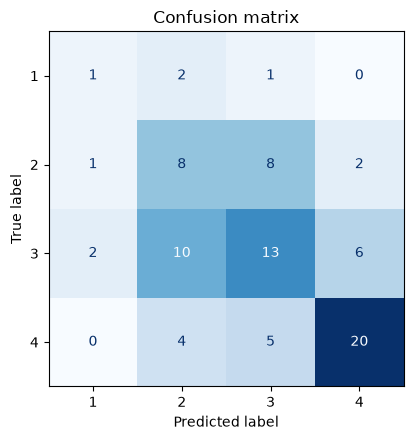

accuracy           0.5060
f1_macro           0.4430
precision_macro    0.4448
recall_macro       0.4450
Name: test metrics, dtype: float64

Baseline f1_macro on test: 0.136


In [16]:
from sklearn import metrics

predictions = final_pipeline.predict(X_test)

if TASK_TYPE == "classification":
    test_metrics = {
        "accuracy": metrics.accuracy_score(y_test, predictions),
        "f1_macro": metrics.f1_score(y_test, predictions, average="macro"),
        "precision_macro": metrics.precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "recall_macro": metrics.recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
    }
    print(metrics.classification_report(
        y_test, predictions, zero_division=0
    ))
    fig, ax = plt.subplots(figsize=(5, 4.5))
    metrics.ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title("Confusion matrix")
    plt.tight_layout()
    plt.show()
else:
    test_metrics = {
        "rmse": metrics.mean_squared_error(y_test, predictions) ** 0.5,
        "mae": metrics.mean_absolute_error(y_test, predictions),
        "r2": metrics.r2_score(y_test, predictions),
    }
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].scatter(y_test, predictions, alpha=0.4)
    limits = [
        min(y_test.min(), predictions.min()),
        max(y_test.max(), predictions.max()),
    ]
    ax[0].plot(limits, limits, "r--")
    ax[0].set_xlabel("Actual")
    ax[0].set_ylabel("Predicted")
    ax[0].set_title("Actual vs. predicted")
    ax[1].hist(y_test - predictions, bins=40)
    ax[1].set_title("Residual distribution")
    plt.tight_layout()
    plt.show()

test_metrics = {k: round(float(v), 4) for k, v in test_metrics.items()}
display(pd.Series(test_metrics, name="test metrics"))

# Baseline on the same test set, to check the model really adds value.
baseline = Pipeline([
    ("prep", preprocessor),
    ("model", candidates["Baseline"]),
]).fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
if TASK_TYPE == "classification":
    baseline_score = metrics.f1_score(
        y_test, baseline_predictions, average="macro"
    )
    print("Baseline f1_macro on test:", round(baseline_score, 4))
else:
    baseline_score = (
        metrics.mean_squared_error(y_test, baseline_predictions) ** 0.5
    )
    print("Baseline RMSE on test:", round(baseline_score, 4))

In [17]:
# The stages are ordered: an error between neighboring stages is less
# serious than one that is two or three stages away.
def ordinal_metrics(y_true, y_pred):
    distance = np.abs(np.asarray(y_true) - np.asarray(y_pred))
    return {
        "accuracy": metrics.accuracy_score(y_true, y_pred),
        "f1_macro": metrics.f1_score(y_true, y_pred, average="macro"),
        "balanced_accuracy": metrics.balanced_accuracy_score(y_true, y_pred),
        "within_one_stage": float((distance <= 1).mean()),
        "mae_stages": float(distance.mean()),
        "quadratic_kappa": metrics.cohen_kappa_score(
            y_true, y_pred, weights="quadratic"
        ),
    }


def rounded(values):
    return {k: round(float(v), 4) for k, v in values.items()}


model_metrics = rounded(ordinal_metrics(y_test, predictions))
baseline_metrics = rounded(ordinal_metrics(y_test, baseline_predictions))
test_metrics.update(model_metrics)
display(pd.DataFrame({"model": model_metrics, "baseline": baseline_metrics}))

# Confusion matrix as a table (rows: actual stage, columns: predicted).
display(pd.crosstab(
    y_test.to_numpy(), predictions, rownames=["actual"],
    colnames=["predicted"],
))
distance = np.abs(y_test.to_numpy() - predictions)
print("Test patients by distance between predicted and real stage:")
print(pd.Series(distance).value_counts().sort_index().to_dict())

,model,baseline
accuracy,0.5060,0.3735
f1_macro,0.4430,0.1360
balanced_accuracy,0.4450,0.2500
within_one_stage,0.8916,0.9518
mae_stages,0.6024,0.6747
quadratic_kappa,0.4856,0.0000


predicted,1,2,3,4
actual,,,,
1,1,2,1,0
2,1,8,8,2
3,2,10,13,6
4,0,4,5,20


Test patients by distance between predicted and real stage:
{0: 42, 1: 32, 2: 9}


In [18]:
# Error analysis: patients in the trial (complete data) vs. patients not
# in the trial (8 of the 15 inputs are imputed).
errors = pd.DataFrame({
    "actual": y_test,
    "predicted": predictions,
    "distance": distance,
    "group": data.loc[X_test.index, "drug"].notna().map(
        {True: "trial", False: "not in trial"}
    ),
})
errors["correct"] = errors["distance"].eq(0)
errors["within_one"] = errors["distance"].le(1)
display(
    errors.groupby("group")
    .agg(n=("actual", "size"), accuracy=("correct", "mean"),
         within_one_stage=("within_one", "mean"),
         mae_stages=("distance", "mean"))
    .round(3)
)
display(
    errors.groupby("actual")
    .agg(n=("actual", "size"), accuracy=("correct", "mean"),
         within_one_stage=("within_one", "mean"),
         mean_predicted=("predicted", "mean"))
    .round(3)
)
print(
    "Predicted stages:",
    errors["predicted"].value_counts().sort_index().to_dict(),
)

# Mean predicted probability of each stage, by actual stage.
probabilities = pd.DataFrame(
    final_pipeline.predict_proba(X_test),
    columns=[f"p(stage {c})" for c in final_pipeline.classes_],
    index=X_test.index,
)
display(probabilities.groupby(y_test).mean().round(3))
print(
    "Mean probability of the predicted stage:",
    round(float(probabilities.max(axis=1).mean()), 3),
)

# Untuned candidate on the same test set, for reference only.
untuned_model = Pipeline([
    ("prep", preprocessor), ("model", candidates[BEST]),
]).fit(X_train, y_train)
print("Untuned", BEST, "on test:")
print(rounded(ordinal_metrics(y_test, untuned_model.predict(X_test))))

,n,accuracy,within_one_stage,mae_stages
group,,,,
not in trial,26,0.538,0.846,0.615
trial,57,0.491,0.912,0.596


,n,accuracy,within_one_stage,mean_predicted
actual,,,,
1,4,0.250,0.750,2.000
2,19,0.421,0.895,2.579
3,31,0.419,0.935,2.742
4,29,0.690,0.862,3.552


Predicted stages: {1: 4, 2: 24, 3: 27, 4: 28}


,p(stage 1),p(stage 2),p(stage 3),p(stage 4)
stage,,,,
1,0.195,0.340,0.302,0.163
2,0.185,0.305,0.322,0.189
3,0.156,0.282,0.321,0.240
4,0.066,0.214,0.278,0.442


Mean probability of the predicted stage: 0.417


Untuned Random Forest (balanced) on test:
{'accuracy': 0.4458, 'f1_macro': 0.4017, 'balanced_accuracy': 0.4489, 'within_one_stage': 0.8916, 'mae_stages': 0.6627, 'quadratic_kappa': 0.5374}


num__platelets         0.1157
num__albumin           0.1052
num__age               0.0992
num__bilirubin         0.0889
num__prothrombin       0.0865
num__sgot              0.0808
num__copper            0.0796
num__cholesterol       0.0708
num__triglycerides     0.0677
num__alk_phos          0.0607
cat__hepatomegaly_N    0.0468
cat__hepatomegaly_Y    0.0349
cat__spiders_Y         0.0183
cat__spiders_N         0.0166
cat__ascites_Y         0.0065
cat__edema_N           0.0065
cat__ascites_N         0.0051
cat__edema_S           0.0042
cat__sex_F             0.0035
cat__sex_M             0.0018
cat__edema_Y           0.0007
Name: Feature importance (impurity), dtype: float64

,mean drop in f1_macro,std
cholesterol,0.0686,0.0232
hepatomegaly,0.0465,0.0383
alk_phos,0.0444,0.0189
triglycerides,0.0438,0.0433
sgot,0.0415,0.0143
bilirubin,0.0395,0.0540
albumin,0.0331,0.0249
prothrombin,0.0195,0.0316
sex,0.0135,0.0068
copper,0.0110,0.0365


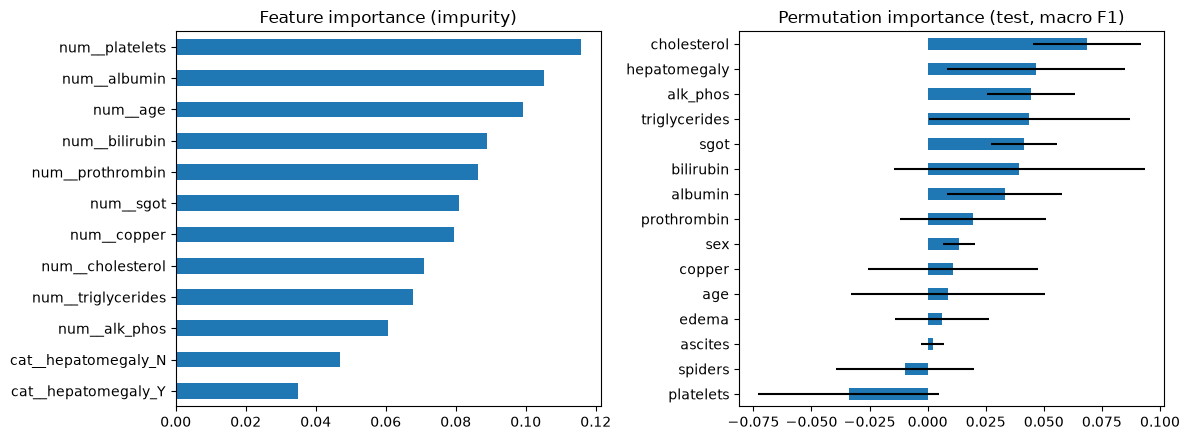

In [19]:
# Feature importance.
from sklearn.inspection import permutation_importance

estimator = final_pipeline.named_steps["model"]
feature_names = final_pipeline.named_steps["prep"].get_feature_names_out()
if hasattr(estimator, "feature_importances_"):
    internal = pd.Series(estimator.feature_importances_, index=feature_names)
    title = "Feature importance (impurity)"
    display(internal.sort_values(ascending=False).round(4).rename(title))
elif hasattr(estimator, "coef_"):
    # One row of coefficients per stage, on standardized inputs.
    coefficients = pd.DataFrame(
        estimator.coef_, index=[f"stage {c}" for c in estimator.classes_],
        columns=feature_names,
    ).T
    display(coefficients.round(3))
    internal = coefficients.abs().mean(axis=1)
    title = "Mean |coefficient| across stages"
else:
    internal = None

# Model-agnostic check on the raw inputs: drop in macro F1 on the test set
# when one input is shuffled (30 repetitions).
permutation = permutation_importance(
    final_pipeline, X_test, y_test, scoring=scoring, n_repeats=30,
    random_state=SEED, n_jobs=1,
)
permuted = pd.DataFrame({
    "mean drop in f1_macro": permutation.importances_mean,
    "std": permutation.importances_std,
}, index=X_test.columns).sort_values("mean drop in f1_macro")
display(permuted.sort_values("mean drop in f1_macro", ascending=False).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
if internal is not None:
    internal.sort_values().tail(12).plot(kind="barh", ax=axes[0], title=title)
permuted["mean drop in f1_macro"].plot(
    kind="barh", ax=axes[1], xerr=permuted["std"],
    title="Permutation importance (test, macro F1)",
)
plt.tight_layout()
plt.show()

**Interpretation.** On the test set (83 patients not used for training) the model reaches **macro F1 0.443**, **balanced accuracy 0.445** and **accuracy 0.506**, against a baseline (always stage 3) with macro F1 **0.136**, balanced accuracy 0.250 and accuracy 0.373. The model learns a real signal, but it assigns the exact stage to only **half of the patients** (42 of 83). The result is in line with the cross-validated estimate (0.435), which gives some confidence that it is not a lucky split; with 83 patients the uncertainty is still large.

**Error analysis (confusion matrix):**
- **By stage:** **stage 4** is clearly the best recognized (precision 0.71, recall 0.69, F1 0.70: 20 of 29 found). **Stage 3** (F1 0.45) and **stage 2** (F1 0.37) are mostly confused with each other: 10 stage 3 patients were predicted as stage 2 and 8 stage 2 patients as stage 3, as the exploration anticipated. **Stage 1** has only 4 test patients, of which 1 was found (F1 0.25); with so few cases that figure says almost nothing.
- **Distance of the errors:** 42 predictions are exact, 32 are one stage away and 9 are two stages away; **none is three stages away** (no stage 1 patient was predicted as stage 4, or the reverse). So **89.2 %** of the predictions are within one stage and the mean absolute error is 0.60 stages; the quadratically weighted kappa is 0.49.
- **Comparison with the baseline on the ordinal view:** **on the "within one stage" metric the majority-class baseline scores higher than the model: 0.952 against 0.892.** Always answering "stage 3" is within one stage for every patient except those of stage 1, because stage 3 is next to stages 2 and 4. On this metric the model does not beat the baseline, and that has to be said next to the 89.2 %. The other ordinal figures favor the model: the baseline never identifies stage 4, the most advanced stage, its mean absolute error is higher (0.67 against 0.60 stages) and its kappa is 0. **No ordinal model was tried**: every candidate treats the four stages as unordered classes, and the ordinal metrics are only reported, not optimized (future work).
- **The worst errors:** 4 of the 29 stage 4 patients were predicted as stage 2 (and 5 as stage 3). Underestimating an advanced patient is the costly mistake in this problem, and it does happen.
- **Confidence:** the mean probability of the predicted stage is only 0.42. The probabilities are flat (for real stage 2 patients the model gives on average 0.31 to stage 2 and 0.32 to stage 3), which reflects how little the inputs separate the stages. The spoken answer includes that probability.
- **Trial vs. non-trial patients:** accuracy is 0.49 on the 57 trial patients and 0.54 on the 26 patients outside the trial, for whom 8 inputs are imputed. The groups are too small for that difference to be meaningful; what it shows is that the model does not collapse when those inputs are missing.

**Effect of tuning.** On the test set the untuned candidate reached a macro F1 of 0.402 and an accuracy of 0.446; the tuned model reached 0.443 and 0.506. The balanced accuracy is practically the same (0.449 untuned against 0.445 tuned) and the weighted kappa of the untuned candidate was higher (0.537 against 0.486). The two are equivalent within the uncertainty of 83 patients. The model chosen by cross-validation is kept; the test set was not used to select it.

**Feature importance.** In the forest's own (impurity) importance the most used variables are **platelets** (0.116), **albumin** (0.105), **age** (0.099), **bilirubin** (0.089) and **prothrombin time** (0.087), followed by the rest of the laboratory values; **hepatomegaly** adds 0.082 between its two columns and is the most important physical finding. Albumin, bilirubin, prothrombin time and age are four of the five variables of the Mayo model of Dickson et al. (1989), and low platelets and low albumin are the pattern seen in stage 4 in section 3. Sex, edema and ascites weigh almost nothing (ascites and severe edema are rare). The **permutation importance on the test set** gives a different order (cholesterol 0.069, hepatomegaly 0.047, alkaline phosphatase 0.044), and for many inputs the standard deviation is as large as the value itself (platelets even comes out negative, -0.034 +/- 0.039). With 83 patients it cannot rank the variables reliably; the importance is spread over many weak inputs, none of them decisive.

**Possible causes of error:** only 412 patients, and 21 of stage 1; 100 of the 412 patients (24.3 %) lack 8 of the 15 inputs, among them the three physical findings `ascites`, `hepatomegaly` and `spiders`, which are imputed with the mode of the training set (`N`, `Y` and `N`), so for those patients these inputs carry no information about the individual (26 of the 83 test patients are in this group); the stage is assigned from a biopsy, which examines a small tissue sample and whose reading may vary; the blood tests change noticeably mainly at stage 4; and neighboring stages are cut points of a continuous process.

## Export for the backend

In [20]:
joblib.dump(
    final_pipeline, ARTIFACTS / f"{MODEL_NAME}.joblib", compress=3
)

# Typical input: becomes the `default_input` of the backend adapter.
example = X_train.median(numeric_only=True).round(3).to_dict()
for column in categorical_features:
    example[column] = X_train[column].mode().iloc[0]

meta = {
    "model": BEST,
    "hyperparameters": HYPERPARAMETERS,
    "task": TASK_TYPE,
    "features": X.columns.tolist(),
    "test_metrics": test_metrics,
    "baseline_test_metrics": baseline_metrics,
    "default_input": example,
    "sklearn_version": sklearn.__version__,
}
if TASK_TYPE == "classification":
    meta["classes"] = sorted(y.unique().tolist())
meta_path = ARTIFACTS / f"{MODEL_NAME}.meta.json"
meta_path.write_text(json.dumps(meta, indent=2, default=str))

print(f"Saved artifacts/{MODEL_NAME}.joblib and {meta_path.name}")
print("\nCopy to backend/models/<package>/ (schema.py / default_input):")
print(json.dumps(example, indent=2, default=str))

Saved artifacts/cirrhosis.joblib and cirrhosis.meta.json

Copy to backend/models/<package>/ (schema.py / default_input):
{
  "age": 51.2,
  "bilirubin": 1.4,
  "cholesterol": 309.0,
  "albumin": 3.52,
  "copper": 73.0,
  "alk_phos": 1282.0,
  "sgot": 116.25,
  "triglycerides": 109.5,
  "platelets": 248.0,
  "prothrombin": 10.6,
  "sex": "F",
  "ascites": "N",
  "hepatomegaly": "Y",
  "spiders": "N",
  "edema": "N"
}


## 6. Conclusion

A Random Forest with balanced class weights estimates the histologic stage (1-4) of primary biliary cirrhosis with a **test macro F1 of 0.44, balanced accuracy of 0.45 and accuracy of 0.51**, against 0.14, 0.25 and 0.37 for the baseline. **This is a modest result and it must be presented as such:** the model gives the exact stage for half of the patients. What it does reasonably well is recognize **stage 4** (F1 0.70), and when it is wrong it is usually by one stage (89 % of the predictions are within one stage, none is three stages away). On that "within one stage" metric, however, the baseline that always answers stage 3 scores higher (95 %) than the model, so the model's advantage is in the exact stage and in recognizing stage 4, not in that figure. The four stages were kept, instead of being merged into an easier problem, because that is what the assignment asks. The model is useful as a **demonstration and as a rough orientation**, not as a replacement for a biopsy or a physician; the assistant says so in every answer.

**Limitations:**
- Small dataset (412 patients, 21 of stage 1) from a single center, collected for a trial decades ago, and only for primary biliary cirrhosis: it does not apply to cirrhosis of other causes (alcohol, viral).
- Stages 2 and 3 are barely distinguishable with these inputs, and 4 of the 29 stage 4 patients in the test set were predicted as stage 2.
- A quarter of the patients (100 of 412, 24.3 %) have 8 of the 15 inputs imputed; for them the physical findings `ascites`, `hepatomegaly` and `spiders` are filled with the mode, a constant that says nothing about the patient.
- No ordinal model was tried: all candidates treat the stages as unordered classes, and on the "within one stage" metric the model (0.892) is below the majority-class baseline (0.952).
- The skewed laboratory values were not transformed; this does not affect the selected forest, but the linear and distance-based candidates were compared without it.
- The test set has 83 patients (4 of stage 1): every metric has a wide margin of uncertainty.
- The predicted probabilities are low (0.42 on average for the predicted stage) and were not calibrated.

**Future improvements:**
- Use an ordinal model that exploits the order of the stages (none was tried here), and tune for a cost that penalizes distant errors.
- Evaluate with repeated or nested cross-validation over all the data to obtain confidence intervals.
- Add missing-value indicators or a model that handles missing values natively, instead of median imputation.
- Report a calibrated probability of stage 4 next to the predicted stage.
- Validate on patients from another center.

**Voice commands for this model:** *"JarvisTEC, cirrhosis stage"*, *"JarvisTEC, stage of cirrhosis"*, *"JarvisTEC, type of cirrhosis"*

### References

- Fleming, T. R., & Harrington, D. P. (1991). *Counting processes and survival analysis*. Wiley.
- Dickson, E. R., Grambsch, P. M., Fleming, T. R., Fisher, L. D., & Langworthy, A. (1989). Prognosis in primary biliary cirrhosis: Model for decision making. *Hepatology, 10*(1), 1-7.
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189-1232. https://doi.org/10.1214/aos/1013203451
- He, H., & Garcia, E. A. (2009). Learning from imbalanced data. *IEEE Transactions on Knowledge and Data Engineering, 21*(9), 1263-1284. https://doi.org/10.1109/TKDE.2008.239
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.